In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo  # noqa: F401
import matplotlib.pyplot as plt
import numpy as np

import pyrite

_ = pyrite.fetch_tables()
tables_ready = True

# Transition and coherent transition radiation

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/10-transition-radiation.py)

Compare transition radiation (TR) from two silicon film thicknesses,
then vary bunch duration to see coherent transition radiation (CTR).
The beam energy is **30 keV** and the observation angle is **150°**.

In [ ]:
from pyrite import simulate
from pyrite.beams import Beam, BunchLength, TransverseSpot
from pyrite.config import CxrReflections, FixedSampling, Numerics, Physics
from pyrite.detectors import Detector, EnergyBins
from pyrite.geometry import Footprint, Slab

tr_detector = Detector(observation_angle_deg=150.0)
tr_numerics = Numerics(
    sampling=FixedSampling(cxr_electrons=64, brem_electrons=128),
    cxr_reflections=CxrReflections(n_families=1),
    energy_model="midpoint",
    seed=1,
    energy_bins=EnergyBins(
        cxr=np.linspace(200.0, 1_000.0, 201), brem=np.array([200.0, 1_000.0])
    ),
)
# Film thickness (Å), RMS bunch duration (fs), coherence.
tr_cases = (
    (100.0, 0.001, "history"),
    (200.0, 0.001, "history"),
    (200.0, 0.001, "bunch"),
    (200.0, 0.1, "bunch"),
)

In [ ]:
assert tables_ready
tr_results = []
for _thickness_ang, _duration_fs, _mode in tr_cases:
    _result = simulate(
        Beam(
            energy_keV=30.0,
            transverse=TransverseSpot(fwhm_x_mm=1e-6),
            longitudinal=BunchLength(rms_fs=_duration_fs),
            bunch_charge_pc=0.0001,
            rep_rate_hz=5_000.0,
        ),
        Slab(
            "silicon",
            thickness_ang=_thickness_ang,
            tilt_deg=5.0,
            footprint=Footprint(5, 5),
        ),
        tr_detector,
        physics=Physics(
            transition_radiation=_mode,
            radiative_model="uncoupled",
            bremsstrahlung_model="eedl",
        ),
        numerics=tr_numerics,
    )
    tr_results.append(_result.transition)

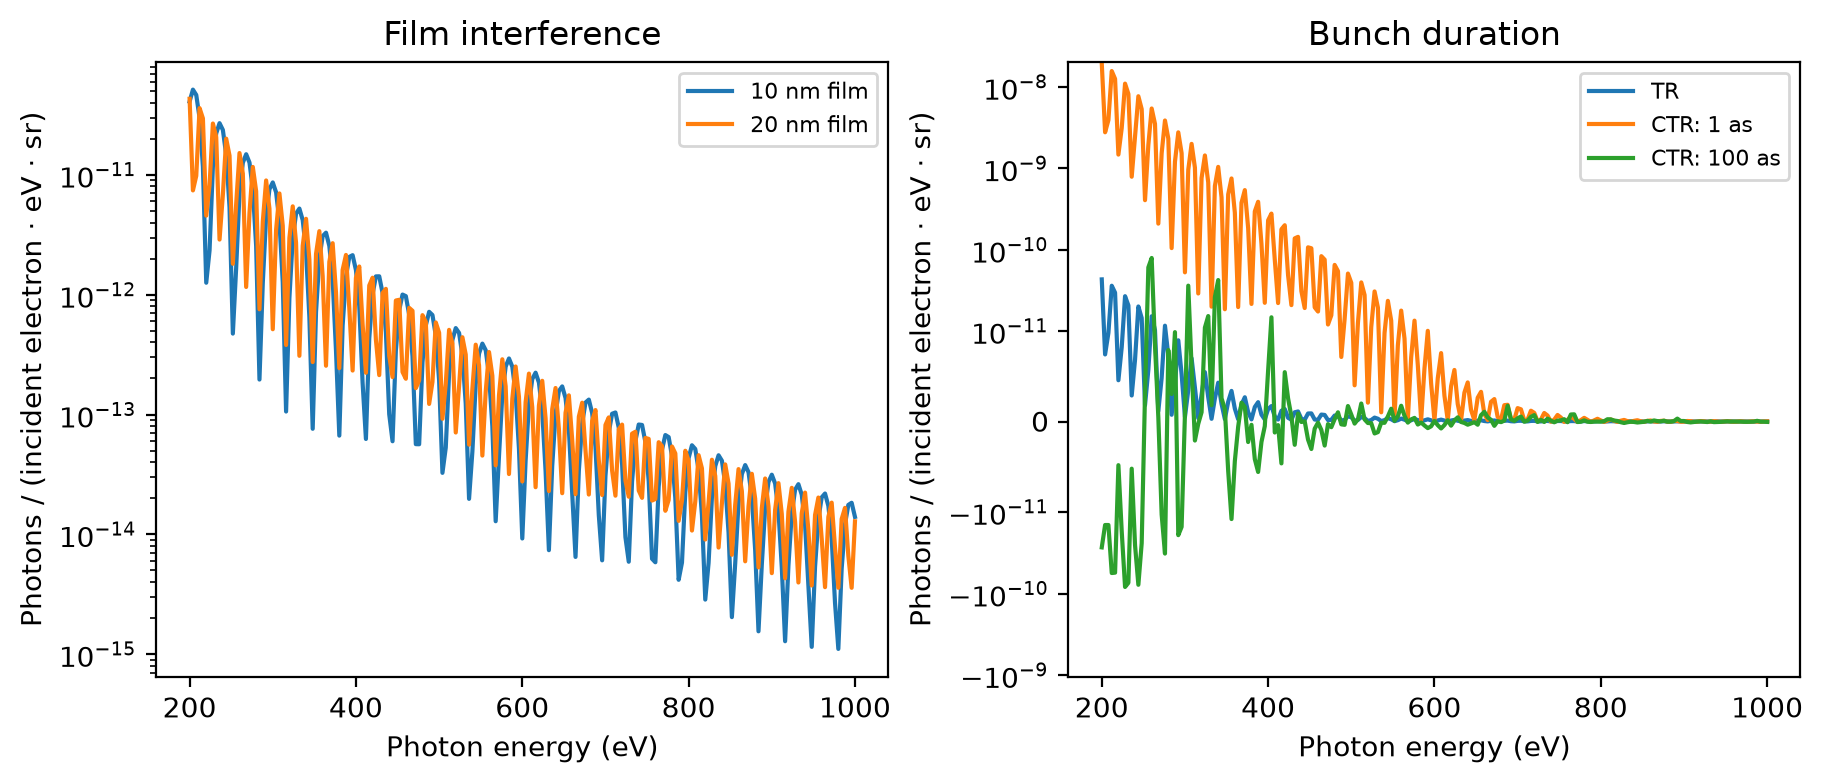

In [ ]:
fig_tr, _axes = plt.subplots(1, 2, figsize=(9, 3.8), layout="constrained", sharex=True)
for _spectrum, _label in zip(tr_results[:2], ("10 nm film", "20 nm film"), strict=True):
    _axes[0].plot(_spectrum.photon_energy_eV, _spectrum.density, label=_label)
for _index, _label in ((1, "TR"), (2, "CTR: 1 as"), (3, "CTR: 100 as")):
    _spectrum = tr_results[_index]
    _axes[1].plot(_spectrum.photon_energy_eV, _spectrum.density, label=_label)
_axes[0].set(title="Film interference", yscale="log")
_axes[1].set_title("Bunch duration")
_axes[1].set_yscale("symlog", linthresh=1e-11)
for _ax in _axes:
    _ax.set(xlabel="Photon energy (eV)", ylabel="Photons / (incident electron · eV · sr)")
    _ax.legend(fontsize=8)
fig_tr  # noqa: B018

Entry and exit fields interfere, making the spectrum depend on film
thickness. A short bunch can add coherently; a longer bunch loses
phase alignment over this X-ray band. The physical bunch contains about
**624 electrons**, independent of the **128 continuum histories** used
for each transported TR estimate (seed 1).

CTR uses a signed finite-sample estimator, so negative samples are retained
on the symmetric logarithmic axis. These are directional source densities,
before detector acceptance. The model assumes flat, laterally infinite
interfaces with a local isotropic dielectric response.

Try increasing the continuum history count to resolve the bunch excess,
or changing film thickness to move the interference fringes.

## Continue learning

See [transition-radiation physics](../../physics/radiation-physics/transition-radiation.md)
for the film model, estimator and validated limits.
The [transported TR/CTR how-to](../../guides/transition-radiation-demo.md) explores the same mechanisms in the application;
the [configuration API](../../reference/python-api/config.md) documents the controls.

{download}`Download canonical Marimo notebook <../10-transition-radiation.py>`